In [59]:
import pandas as pd                     
import numpy as np                      
import matplotlib.pyplot as plt   
import seaborn as sns      

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score

print("Libraries imported successfully")


Libraries imported successfully


In [60]:
df=pd.read_csv("Predict dropout rate (csvfile dataset).csv")
print("Dataset shape (rows, columns):", df.shape)

df.head()

Dataset shape (rows, columns): (4424, 35)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


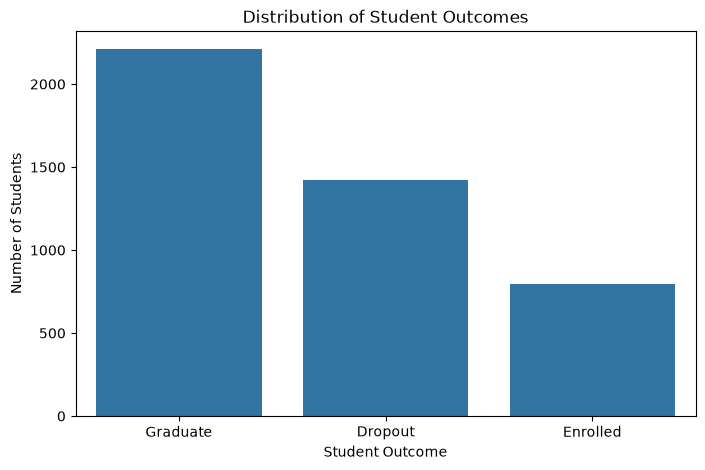

In [61]:
# graph showing how many students were Graduated/Dropout/Enrolled

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Target',
    order=['Graduate', 'Dropout', 'Enrolled']
)

plt.title("Distribution of Student Outcomes")
plt.xlabel("Student Outcome")
plt.ylabel("Number of Students")

plt.show()

In [62]:
y=df["Target"]
y_list=y.tolist()
# Dropping useless column with almost zero to none variation 
X=df.drop(columns=(["Nacionality","Educational special needs","Target"])).copy()
X.shape

(4424, 32)

In [63]:
# columns with in which different numbers represent different things 
categorial_column=[
    'Marital status',
    'Application mode',
    'Course',
    'Previous qualification',
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# columns with 0/1 as data
# Columns -> Gender and Daytime/evening attendance are binary categorial i.e they are dont answer yes/no but something else like male=1 & female=0, day=1 & evening=0
binary_column= [
    'Daytime/evening attendance',
    'Displaced',
    'Debtor',
    'Tuition fees up to date',
    'Gender',
    'Scholarship holder',
    'International'
]

# column with actual numerical data 
numeric_column=[
   col for col in X.columns
    if col not in categorial_column+binary_column
]

In [64]:
df_num=X[numeric_column]
df_bi=X[binary_column]
df_cat=X[categorial_column]

In [65]:
print(f"Size of numerical columns : {df_num.shape}")
cn_list=df_num.columns.tolist()
print(f"Name of columns : ")
print(f"{cn_list}\n")
print("-------------------------------------------------------")
print("Number of nulls in each columns-->\n")
print(df_num.isnull().sum())
print("-------------------------------------------------------")
df_num.describe()

Size of numerical columns : (4424, 17)
Name of columns : 
['Application order', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']

-------------------------------------------------------
Number of nulls in each columns-->

Application order                                 0
Age at enrollment                                 0
Curricular units 1st sem (credited)               0
Curricular units 1st sem (enrolled)               0
Curricular units 1st sem (evaluations)            0
Curricular

,Application order,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.727848,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,1.313793,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,2.000000,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,9.000000,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


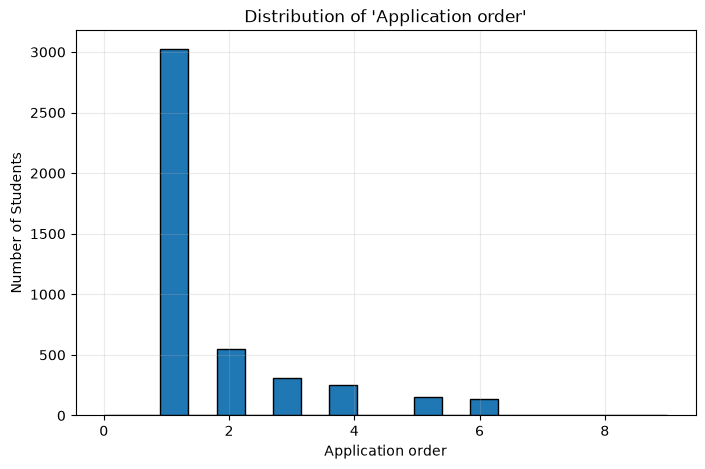

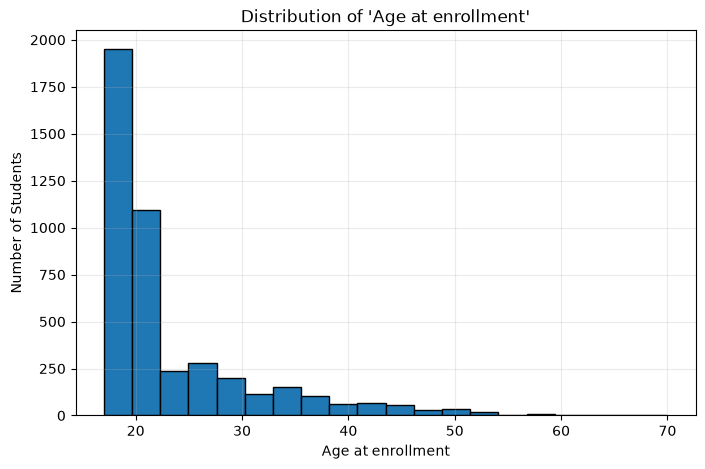

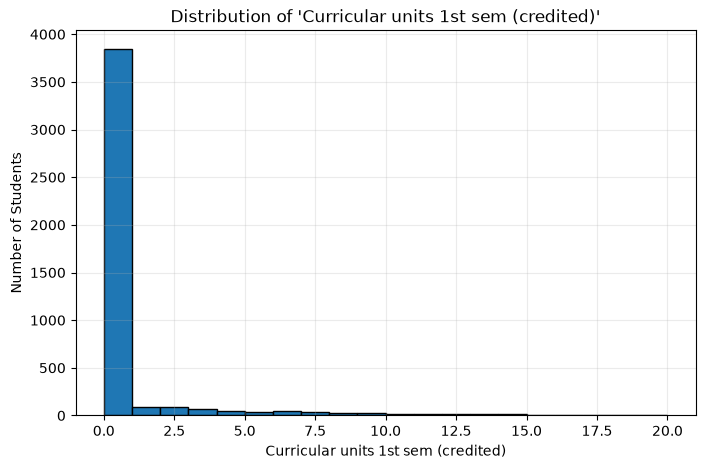

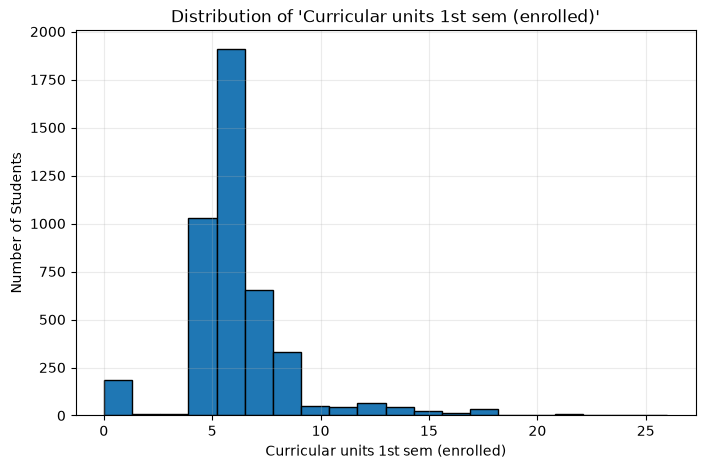

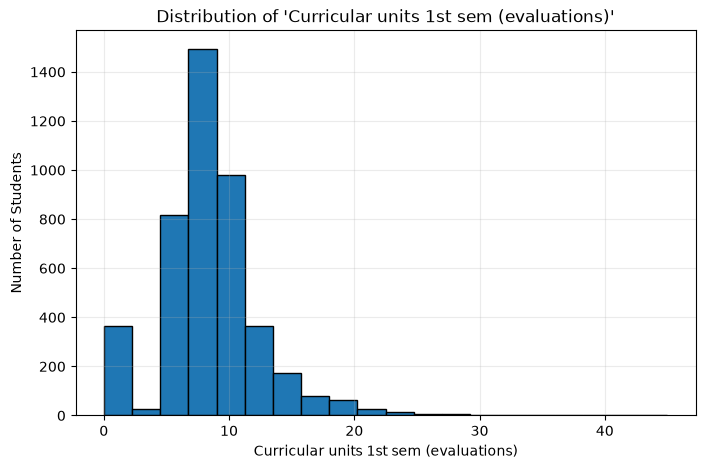

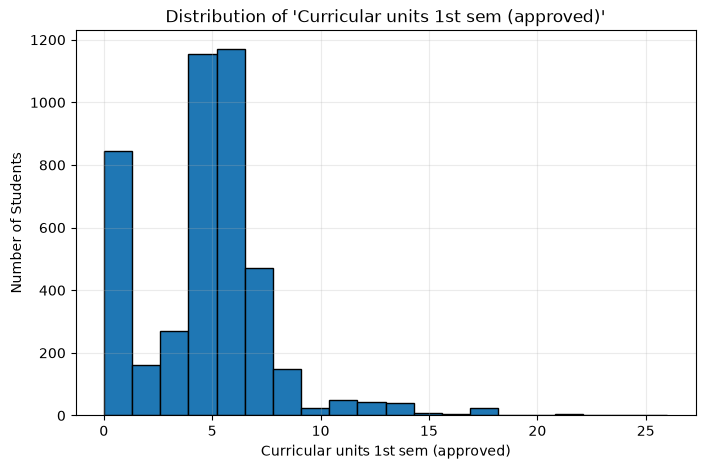

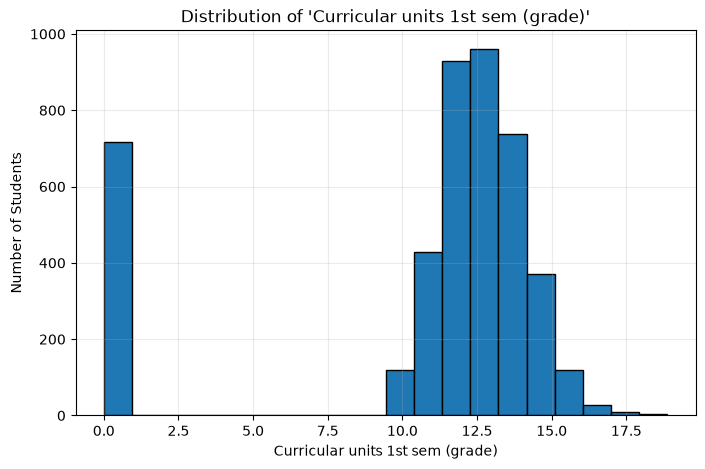

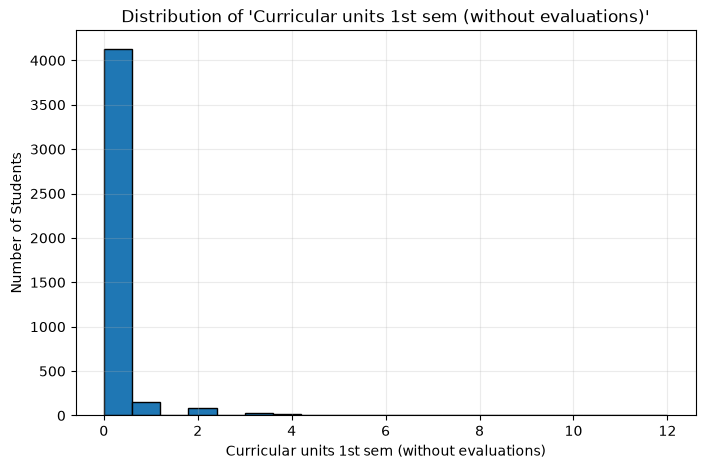

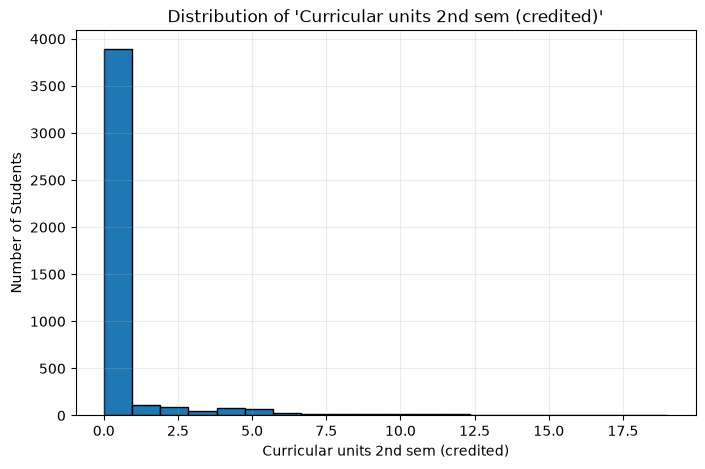

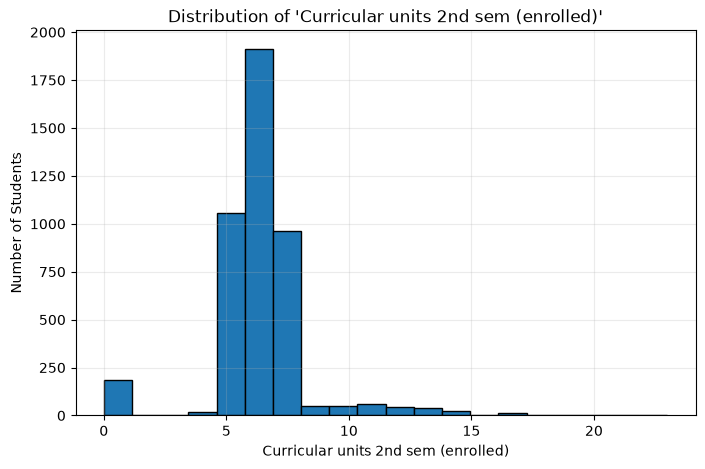

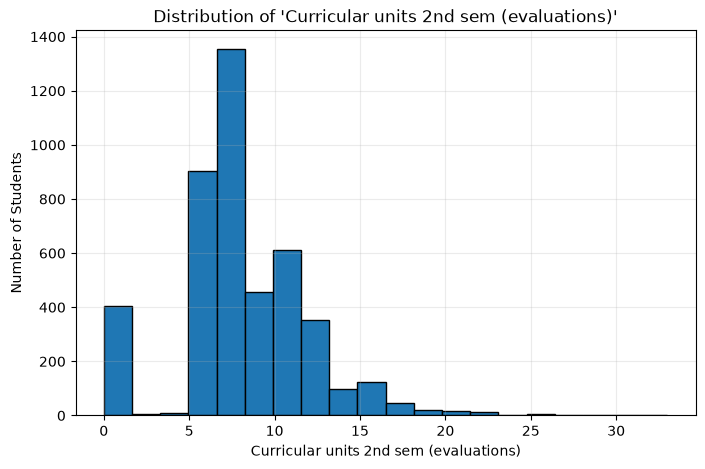

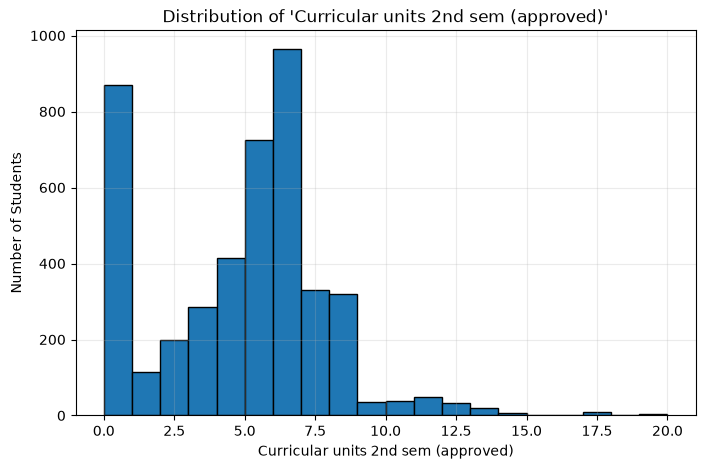

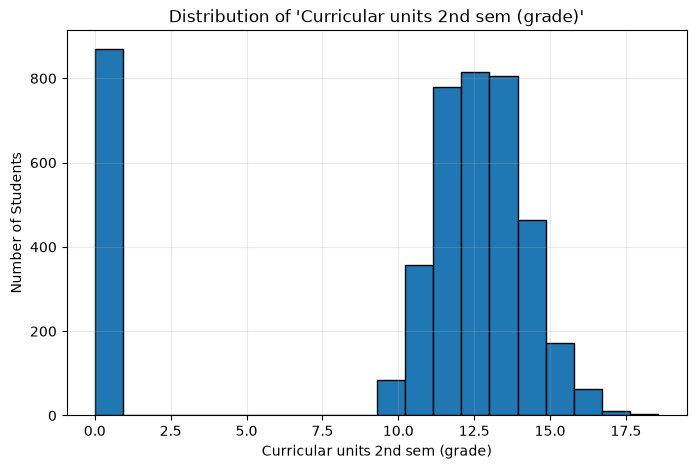

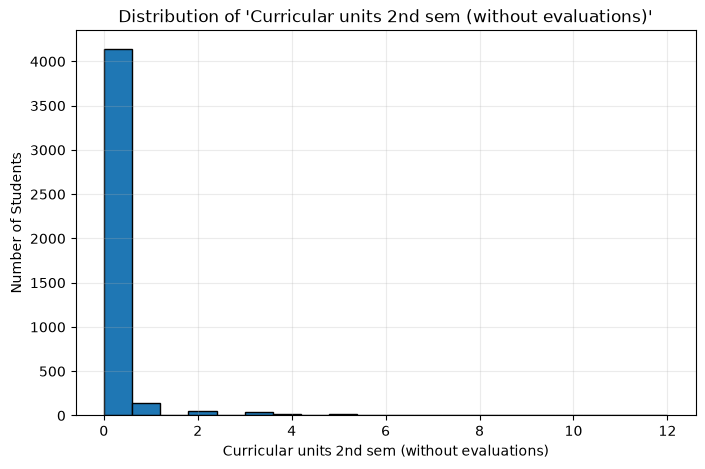

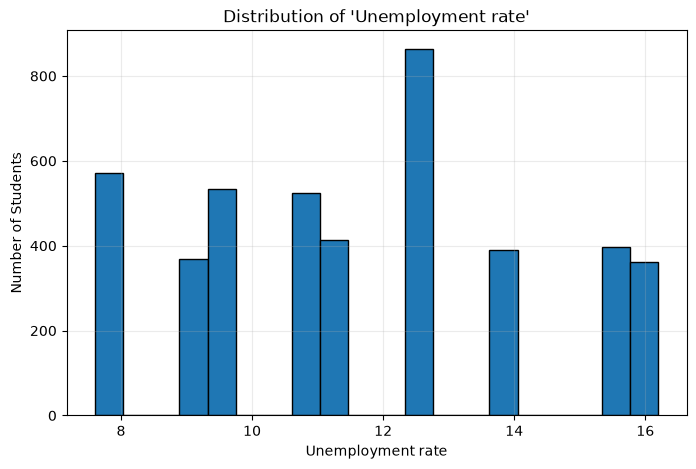

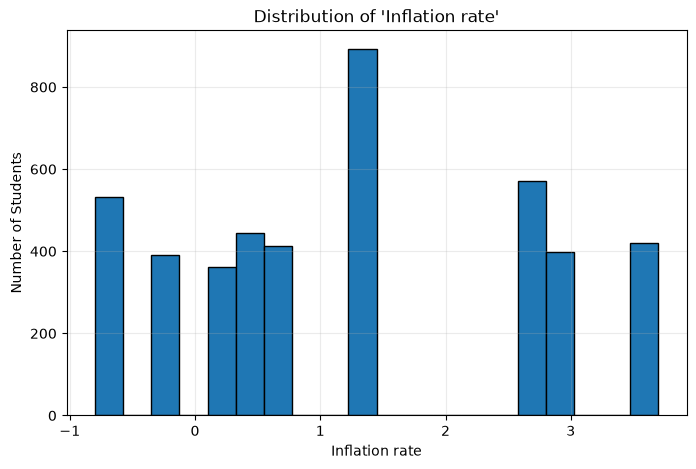

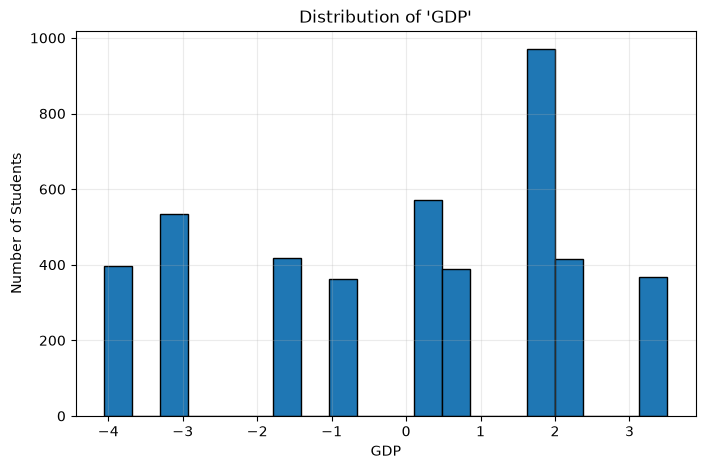

In [66]:
# analysis of numerical columns graphically
def plt_grph(af,x):
    plt.figure(figsize=(8, 5))
    plt.hist(af[x], bins=20, edgecolor="black")
    plt.title(f"Distribution of '{x}'")
    plt.xlabel(x)
    plt.ylabel("Number of Students")
    plt.grid(alpha=0.25)
    plt.show()
        
for i in cn_list:
    plt_grph(df_num,i)
    print()

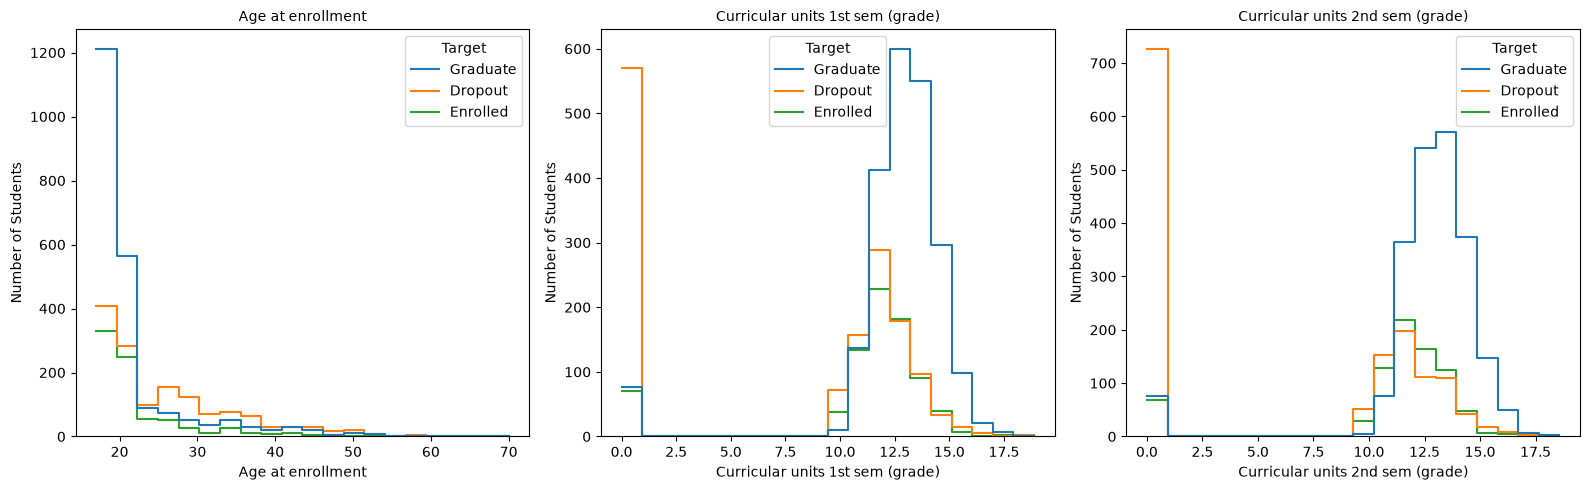

In [67]:
# graph explaining whether age or academic grading affects graduate/dropout rates

key_columns = [
    'Age at enrollment',
    'Curricular units 1st sem (grade)',
    'Curricular units 2nd sem (grade)'
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col in zip(axes, key_columns):

    sns.histplot(
        data=df,
        x=col,
        hue='Target',
        hue_order=['Graduate', 'Dropout', 'Enrolled'],
        bins=20,
        element='step',
        fill=False,
        ax=ax
    )

    ax.set_title(col, fontsize=10)
    ax.set_xlabel(col)
    ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [68]:
# analysing binary columns
print(f"Size of binary columns : {df_bi.shape}")
cb_list=df_bi.columns.tolist()
print(f"Name of columns : ")
print(f"{cb_list}\n")
print("-------------------------------------")
print("Number of nulls in each columns-->\n")
print(df_bi.isnull().sum())
print("-------------------------------------")
num_1=np.array(df_bi.sum(axis=0).tolist())
per_1=num_1*100/df_bi.shape[0]
num_0=df_bi.shape[0]-num_1
per_0=100-per_1
bi_analy=pd.DataFrame({
    "Column name":cb_list,
    "Number of 1s":num_1,
    "Number of 0s":num_0,
    "Percentage of 1s":per_1,
    "Percentage of 0s":per_0
})
bi_analy

Size of binary columns : (4424, 7)
Name of columns : 
['Daytime/evening attendance', 'Displaced', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

-------------------------------------
Number of nulls in each columns-->

Daytime/evening attendance    0
Displaced                     0
Debtor                        0
Tuition fees up to date       0
Gender                        0
Scholarship holder            0
International                 0
dtype: int64
-------------------------------------


,Column name,Number of 1s,Number of 0s,Percentage of 1s,Percentage of 0s
0,Daytime/evening attendance,3941,483,89.082278,10.917722
1,Displaced,2426,1998,54.837251,45.162749
2,Debtor,503,3921,11.369801,88.630199
3,Tuition fees up to date,3896,528,88.065099,11.934901
4,Gender,1556,2868,35.171790,64.828210
5,Scholarship holder,1099,3325,24.841772,75.158228
6,International,110,4314,2.486438,97.513562


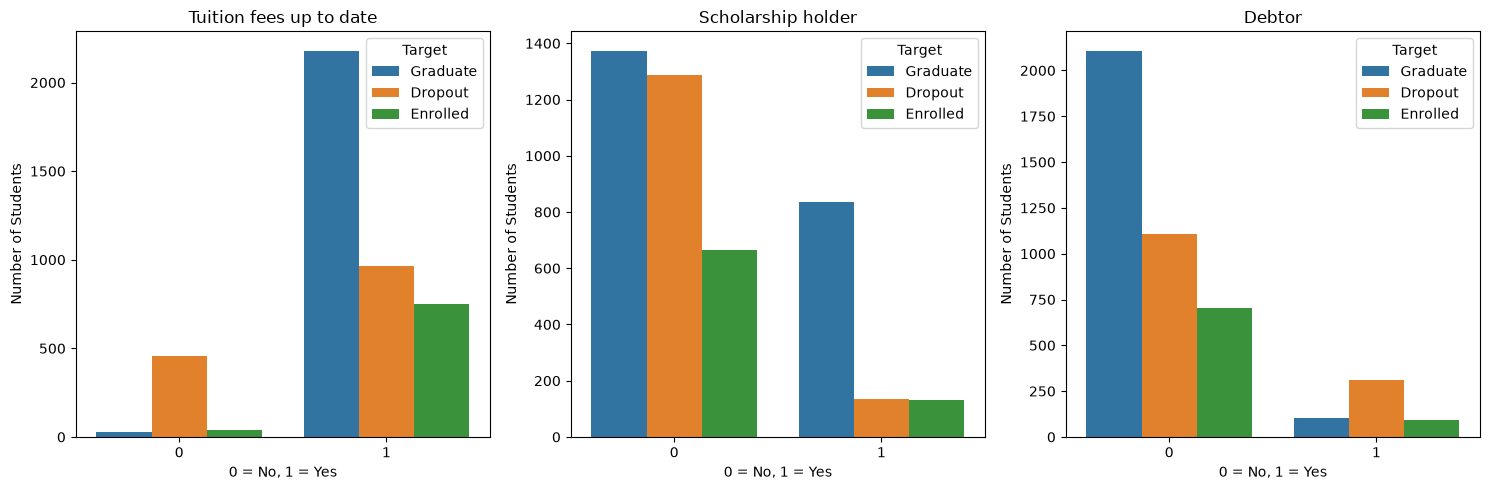

In [69]:
# graphically understanding wheteher features like up to the date tution fee and other features help us to distinct graduate/dropouts/enrolled students

cols = ['Tuition fees up to date','Scholarship holder','Debtor']


fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, cols):

    sns.countplot(
        data=df,
        x=col,
        hue='Target',
        hue_order=['Graduate', 'Dropout', 'Enrolled'],
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel("0 = No, 1 = Yes")
    ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [70]:
# analysing categorial columns 
print(f"Size of binary columns : {df_cat.shape}")
cc_list=df_cat.columns.tolist()
print(f"Name of columns : ")
print(f"{cc_list}\n")
print("-------------------------------------")
print("Number of nulls in each columns-->\n")
print(df_cat.isnull().sum())
print("-------------------------------------")
# defining function too make number of categories for df_cat
def cat_num(af,x):
    g=[]
    for i in x:
        k=0
        l=[]
        for j in af[i]:
            if j not in l:
                l.append(j)
                k+=1

        g.append(k)

    return pd.DataFrame({"Column name":x,"Number of categories":g})

cc_analy=cat_num(df_cat,cc_list)
cc_analy

Size of binary columns : (4424, 8)
Name of columns : 
['Marital status', 'Application mode', 'Course', 'Previous qualification', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

-------------------------------------
Number of nulls in each columns-->

Marital status            0
Application mode          0
Course                    0
Previous qualification    0
Mother's qualification    0
Father's qualification    0
Mother's occupation       0
Father's occupation       0
dtype: int64
-------------------------------------


,Column name,Number of categories
0,Marital status,6
1,Application mode,18
2,Course,17
3,Previous qualification,17
4,Mother's qualification,29
5,Father's qualification,34
6,Mother's occupation,32
7,Father's occupation,46


In [71]:
# created preprocessing pipeline


preprocess=ColumnTransformer(
    transformers=[
        ('category',
        OneHotEncoder(
                handle_unknown='infrequent_if_exist',
                min_frequency=10
            ),
            categorial_column
        ),
        ('numeric',
        StandardScaler(),
        numeric_column
        ),
        ('binary',
        'passthrough',
        binary_column
        )
    ]
)
print("Preprocessing pipeline formed successfully")

Preprocessing pipeline formed successfully


In [72]:
# creating pipleine to train the model
model=Pipeline(steps=[
    ('tranform',preprocess),
    ('classi',LogisticRegression(max_iter=3000,class_weight=None))
])
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tranform', ...), ('classi', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Dropout','Enrolled','Graduate']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](32,)","['Marital status','Application mode','Application order',..., 'Unemployment rate','Inflation rate','GDP']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,32
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('category', ...), ('numeric', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are droppe

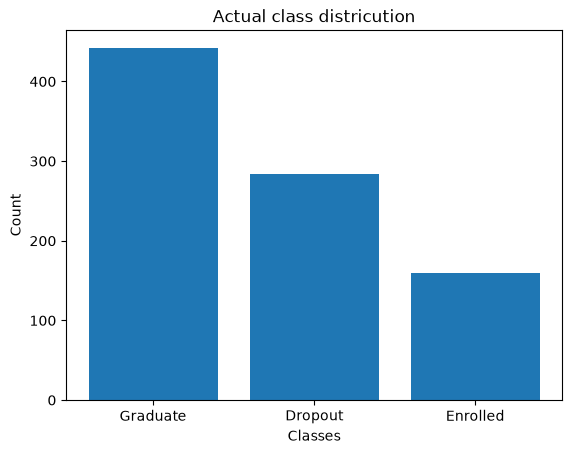

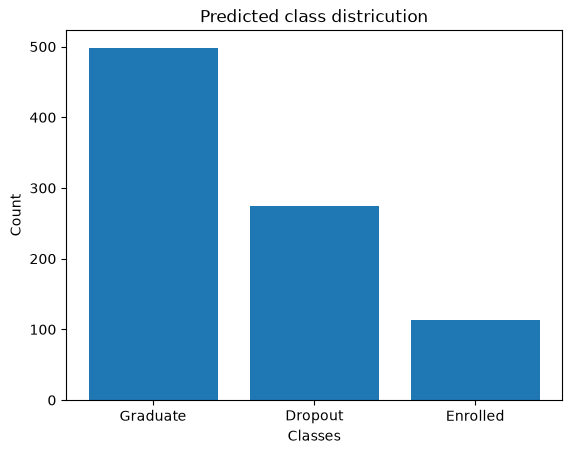

In [73]:
# analysis of result through graphs
y_act=y_test.tolist()
y_pred=model.predict(X_test).tolist()
output_str=["Graduate","Dropout","Enrolled"]
def count_cls(l):
    return [l.count("Graduate"),l.count("Dropout"),l.count("Enrolled")]

plt.bar(output_str,count_cls(y_act))
plt.title("Actual class districution")
plt.xlabel("Classes")
plt.ylabel("Count")
plt.show()
print()
plt.bar(output_str,count_cls(y_pred))
plt.title("Predicted class districution")
plt.xlabel("Classes")
plt.ylabel("Count")
plt.show()
    

In [74]:
# analysis of result using accuracy, f1_score,Confusion matrix etc..
print('Accuracy', accuracy_score(y_act,y_pred))
print("Macro F1:", f1_score(
    y_act, y_pred, average='macro'
))
print("Weighted F1:", f1_score(
    y_act, y_pred, average='weighted'
))

print()
print("Confusion matrix of a 3 class system ")
print(confusion_matrix(y_act,y_pred))
print()
print("-------------------------------------------------------------------------------------")
print("Final classification report including precision,recall and f1-score for each class\n")
print(classification_report(
    y_act, y_pred,
    zero_division=0
))
print("-------------------------------------------------------------------------------------")

Accuracy 0.7717514124293785
Macro F1: 0.69900110352995
Weighted F1: 0.7609686942375802

Confusion matrix of a 3 class system 
[[216  30  38]
 [ 40  63  56]
 [ 18  20 404]]

-------------------------------------------------------------------------------------
Final classification report including precision,recall and f1-score for each class

              precision    recall  f1-score   support

     Dropout       0.79      0.76      0.77       284
    Enrolled       0.56      0.40      0.46       159
    Graduate       0.81      0.91      0.86       442

    accuracy                           0.77       885
   macro avg       0.72      0.69      0.70       885
weighted avg       0.76      0.77      0.76       885

-------------------------------------------------------------------------------------


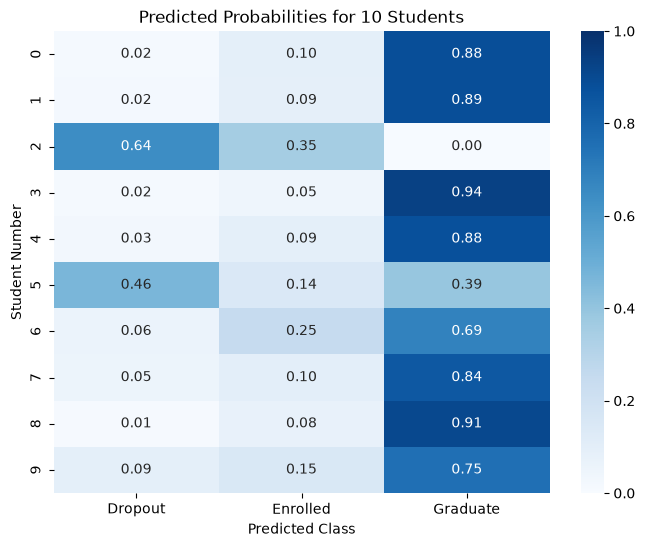

In [75]:
# Graphically understanding probability distibution for 10 students


y_probs = model.predict_proba(X_test)


class_names = model.named_steps['classi'].classes_


prob_df = pd.DataFrame(
    y_probs[:10],
    columns=class_names
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    prob_df,
    annot=True,
    fmt='.2f',
    cmap='Blues',
    vmin=0,
    vmax=1
)

plt.title("Predicted Probabilities for 10 Students")
plt.xlabel("Predicted Class")
plt.ylabel("Student Number")

plt.show()